# Pergunta 1.1: qual o perfil geral dos dados?

> **Pergunta do case:** qual o perfil geral dos dados? Distribuições, valores faltantes, outliers. Como você trataria cada caso?

Cada linha da base é um **criativo** (um vídeo de anúncio), com os atributos do vídeo, o contexto da campanha e as métricas de resultado. A nota que a Parte 2 vai prever é o `klike_score` (0 a 100).

| Passo | Pergunta | O que decide |
|---|---|---|
| 1 | Como separar treino e teste? | qual parte dos dados eu posso olhar |
| 2 | O que tem na base? | o tamanho, os tipos e as combinações que não existem |
| 3 | Como os números se distribuem? | usar média ou mediana; usar log nos gráficos |
| 4 | As contas entre as métricas batem? | quais linhas têm erro e como corrigir |
| 5 | O que está faltando, e como preencher? | o tratamento de cada coluna com vazios |
| 6 | Quais valores são extremos? Erro ou verdade? | o que corrigir e o que manter |
| 7 | Que colunas novas criar? | as colunas que a Parte 2 vai usar |
| 8 | A limpeza reaproveitável dá o mesmo resultado? | o arquivo limpo que as próximas partes usam |

A explicação de cada decisão está em `docs/parte1/1_1_perfil_dos_dados.md`.

## Passo 0: preparação

In [1]:
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# O notebook fica em notebooks/parte1; a raiz do projeto fica duas pastas acima
RAIZ = Path("../..")
sys.path.append(str(RAIZ))  # permite importar o src/limpeza.py no passo 8

pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 200)

AZUL, CINZA = "#2a78d6", "#52514e"  # cor principal e cor de referência
CORES_PLATAFORMA = {"Meta": "#2a78d6", "TikTok": "#eb6834", "LinkedIn": "#1baf7a"}  # a mesma cor em todo o projeto


def estilo_limpo(ax):
    """Tira as bordas de cima e da direita e deixa a grade discreta."""
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis="y", color="#e5e5e5", linewidth=0.8)
    ax.set_axisbelow(True)

In [2]:
bruto = pd.read_csv(RAIZ / "data/raw/klike_challenge_dataset.csv")
bruto["date"] = pd.to_datetime(bruto["date"])  # a data chega como texto
print(bruto.shape)
bruto.head(3)

(500, 26)


,campaign_id,date,platform,category,objective,target_audience_age,is_retargeting,video_duration_s,format,has_subtitle,has_cta,has_hook,has_face,text_density,music_voice_ratio,impressions,clicks,ctr,cpc,spend,conversions,revenue,roas,avg_watch_time_s,engagement_rate,klike_score
0,KLK-0001,2024-01-01,Meta,Branding,awareness,18-24,False,NaN,vertical,True,True,False,True,medium,0.39,150825,5882,0.0390,0.82,4823.24,48,0.00,0.00,3.9,0.0446,63.6
1,KLK-0002,2024-03-22,LinkedIn,App Install,traffic,25-34,False,NaN,horizontal,True,True,True,True,low,0.07,7433,493,0.0664,3.54,1745.22,34,NaN,0.16,6.4,0.0217,70.0
2,KLK-0003,2024-05-04,TikTok,SaaS,traffic,25-34,False,8.0,vertical,True,True,True,True,medium,0.43,193198,15069,0.0780,0.38,5726.22,492,51053.44,8.92,8.0,0.1000,99.1


## Passo 1: separar treino e teste antes de olhar os dados

A Parte 2 vai treinar um modelo e medir a nota dele no **teste**. O teste é como a prova guardada na gaveta: se eu olhar para ele agora, o que eu aprender (qual atributo parece bom, qual valor usar para preencher vazios) contamina a nota final. Por isso separo antes de qualquer análise e, daqui em diante, **olho só o treino**.

- `test_size=0.2`: 20% dos criativos vão para o teste;
- `random_state=42`: a "semente" do sorteio; com ela fixa, o sorteio sai sempre igual e os números do notebook não mudam a cada execução;
- `stratify=platform`: o sorteio respeita a proporção de cada plataforma. O LinkedIn tem poucos criativos; sem isso, o teste poderia ficar com quase nenhum.

In [3]:
from sklearn.model_selection import train_test_split

treino, teste = train_test_split(bruto, test_size=0.2, random_state=42, stratify=bruto["platform"])

# Conferências: nenhuma linha perdida, nenhuma linha nas duas partes
assert len(treino) + len(teste) == len(bruto)
assert not set(treino["campaign_id"]) & set(teste["campaign_id"])

pd.DataFrame({
    "treino": treino["platform"].value_counts(),
    "teste": teste["platform"].value_counts(),
    "% no treino": (treino["platform"].value_counts(normalize=True) * 100).round(1),
    "% no teste": (teste["platform"].value_counts(normalize=True) * 100).round(1),
})

,treino,teste,% no treino,% no teste
platform,,,,
Meta,193,48,48.2,48.0
TikTok,141,35,35.2,35.0
LinkedIn,66,17,16.5,17.0


## Passo 2: o que tem na base?

In [4]:
print(f"Treino: {treino.shape[0]} criativos e {treino.shape[1]} colunas")
print(f"Período: {treino['date'].min():%d/%m/%Y} a {treino['date'].max():%d/%m/%Y}")
print(f"campaign_id repetido: {treino['campaign_id'].duplicated().sum()} | linhas inteiras repetidas: {treino.duplicated().sum()}")
treino.info()

Treino: 400 criativos e 26 colunas
Período: 01/01/2024 a 30/12/2024
campaign_id repetido: 0 | linhas inteiras repetidas: 0
<class 'pandas.DataFrame'>
Index: 400 entries, 56 to 228
Data columns (total 26 columns):
 #   Column               Non-Null Count  Dtype         
---  ------               --------------  -----         
 0   campaign_id          400 non-null    str           
 1   date                 400 non-null    datetime64[us]
 2   platform             400 non-null    str           
 3   category             400 non-null    str           
 4   objective            400 non-null    str           
 5   target_audience_age  400 non-null    str           
 6   is_retargeting       400 non-null    bool          
 7   video_duration_s     370 non-null    float64       
 8   format               400 non-null    str           
 9   has_subtitle         364 non-null    object        
 10  has_cta              400 non-null    bool          
 11  has_hook             400 non-null    bool

**Frequência de cada categoria.** Para colunas de texto, o que importa é quantos criativos há em cada categoria.

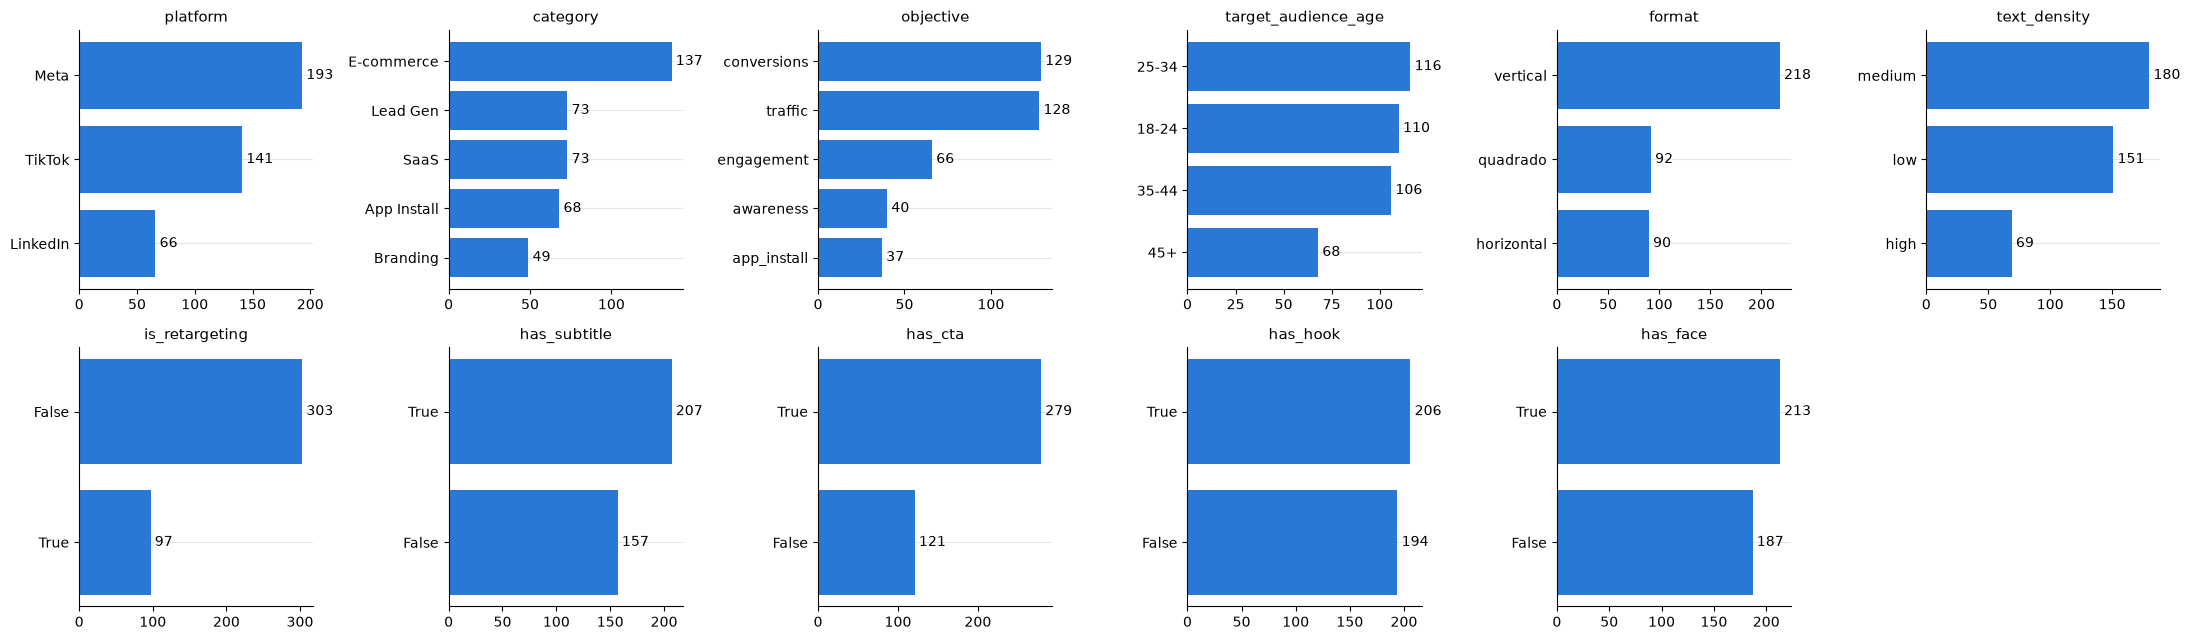

In [5]:
colunas_categoricas = ["platform", "category", "objective", "target_audience_age", "format", "text_density",
                       "is_retargeting", "has_subtitle", "has_cta", "has_hook", "has_face"]

fig, eixos = plt.subplots(2, 6, figsize=(22, 6.5))
for ax, coluna in zip(eixos.flat, colunas_categoricas):
    contagem = treino[coluna].astype(str).value_counts()
    barras = ax.barh(contagem.index[::-1], contagem.values[::-1], color=AZUL)
    ax.bar_label(barras, padding=3, fontsize=10)
    ax.set_title(coluna, fontsize=11)
    estilo_limpo(ax)
eixos.flat[-1].remove()
plt.tight_layout()
plt.show()

**Combinações entre categorias.** `pd.crosstab` conta quantos criativos há em cada combinação de duas colunas. Procuro células vazias ou muito pequenas, que limitam o que dá para concluir depois.

Para resumir cada tabela num número uso o **V de Cramér**: vai de 0 (as duas colunas não têm nada a ver uma com a outra) a 1 (uma coluna define a outra). É como a correlação, só que para colunas de texto. A conta compara cada célula com o número que ela teria se as duas colunas fossem independentes.

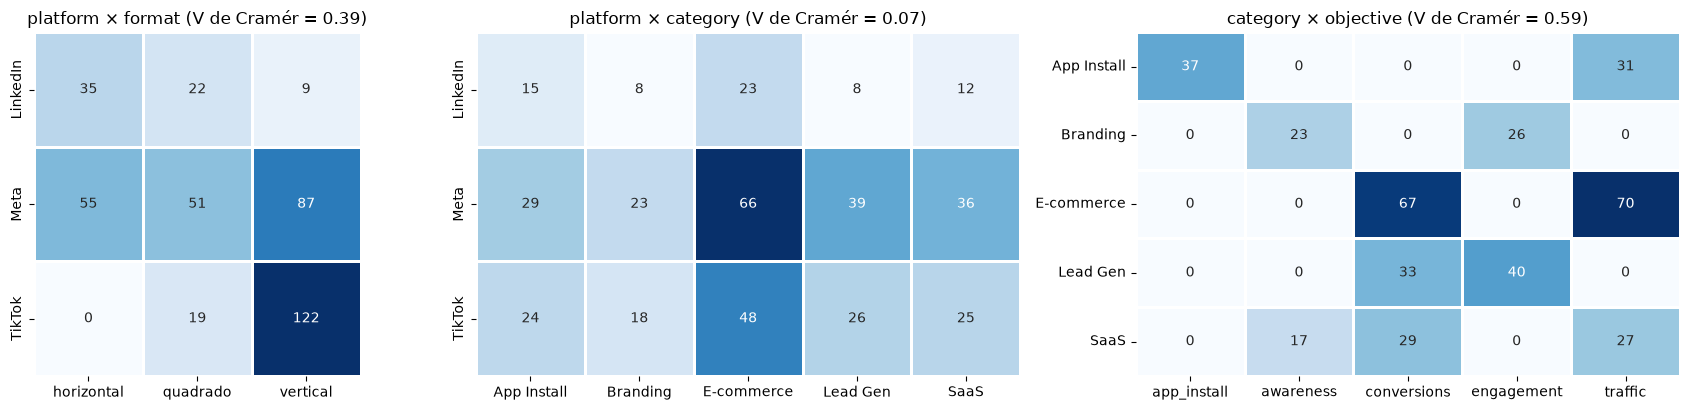

In [6]:
def v_de_cramer(coluna_a, coluna_b):
    """0 = as colunas não têm relação; 1 = uma define a outra."""
    tabela = pd.crosstab(coluna_a, coluna_b).to_numpy()
    total = tabela.sum()
    # Quanto haveria em cada célula se as colunas fossem independentes
    esperado = tabela.sum(axis=1, keepdims=True) * tabela.sum(axis=0, keepdims=True) / total
    distancia = ((tabela - esperado) ** 2 / esperado).sum()  # quanto a tabela real foge do "independente"
    return np.sqrt(distancia / (total * (min(tabela.shape) - 1)))


pares = [("platform", "format"), ("platform", "category"), ("category", "objective")]
fig, eixos = plt.subplots(1, 3, figsize=(17, 4.2), gridspec_kw={"width_ratios": [3, 5, 5]})
for ax, (linha, coluna) in zip(eixos, pares):
    tabela = pd.crosstab(treino[linha], treino[coluna])
    sns.heatmap(tabela, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax, linewidths=2, linecolor="white")
    ax.set_title(f"{linha} × {coluna} (V de Cramér = {v_de_cramer(treino[linha], treino[coluna]):.2f})")
    ax.set_xlabel("")
    ax.set_ylabel("")
plt.tight_layout()
plt.show()

**Lendo as tabelas:**

- **400 criativos** no treino, 26 colunas, veiculados ao longo de 2024; nenhum id nem linha repetidos.
- **Plataformas desbalanceadas:** Meta 193, TikTok 141, LinkedIn só 66. Tudo o que eu disser sobre o LinkedIn terá mais incerteza.
- **O TikTok não tem nenhum vídeo horizontal** e o LinkedIn tem só 9 verticais (V de Cramér plataforma × formato = 0,39). Então não dá para comparar os três formatos dentro de cada rede.
- **`objective` é quase definido por `category`** (V de Cramér = 0,59; Branding, por exemplo, só roda awareness e engagement). As duas colunas repetem informação: numa regressão, o peso de cada uma fica instável. Como elas só entram como controle, isso não atrapalha.

## Passo 3: como os números se distribuem?

Três medidas para cada coluna numérica:
- **média e mediana:** a mediana é o valor do meio. Se entrar um bilionário numa sala, a média de renda dispara e a mediana quase não muda. Média muito acima da mediana = alguns valores enormes puxando a média;
- **skew (assimetria):** 0 numa distribuição simétrica; quanto maior, mais longa a "cauda" de valores grandes à direita.

In [7]:
colunas_numericas = ["video_duration_s", "music_voice_ratio", "impressions", "clicks", "ctr", "cpc", "spend",
                     "conversions", "revenue", "roas", "avg_watch_time_s", "engagement_rate", "klike_score"]
resumo = treino[colunas_numericas].describe().T
resumo["skew"] = treino[colunas_numericas].skew()
resumo["média / mediana"] = resumo["mean"] / resumo["50%"]
resumo.round(3)

,count,mean,std,min,25%,50%,75%,max,skew,média / mediana
video_duration_s,370.0,19.738,14.240,5.000,11.000,16.000,25.000,115.00,2.620,1.234
music_voice_ratio,371.0,0.398,0.199,0.020,0.230,0.390,0.550,0.92,0.203,1.021
impressions,400.0,181050.192,1308569.216,1000.000,9312.000,23541.000,57668.500,14052761.00,9.823,7.691
clicks,400.0,3644.972,7304.316,4.000,444.250,1364.500,3610.000,72545.00,5.336,2.671
ctr,400.0,0.071,0.045,0.002,0.032,0.064,0.105,0.15,0.413,1.112
cpc,380.0,1.140,2.140,0.150,0.520,0.710,1.020,26.05,9.356,1.605
spend,400.0,3924.424,10183.020,2.960,322.782,1050.660,2886.100,95811.69,5.741,3.735
conversions,400.0,136.382,327.027,0.000,10.000,35.000,118.000,3666.00,6.052,3.897
revenue,378.0,6296.122,19908.020,0.000,280.542,1224.270,4325.120,241597.29,8.947,5.143
roas,400.0,2.463,3.178,0.000,0.440,1.590,3.190,27.42,3.097,1.549


**Histogramas.** Para as métricas de volume (impressions, clicks, spend, conversions, revenue, roas, cpc) uso **log1p**, que é `log(1 + x)`. O log "aperta" os números grandes: sem ele, uma campanha gigante espreme todas as outras numa barra só. O "1 +" evita o problema do log de zero (algumas campanhas têm revenue = 0). Linha tracejada = mediana.

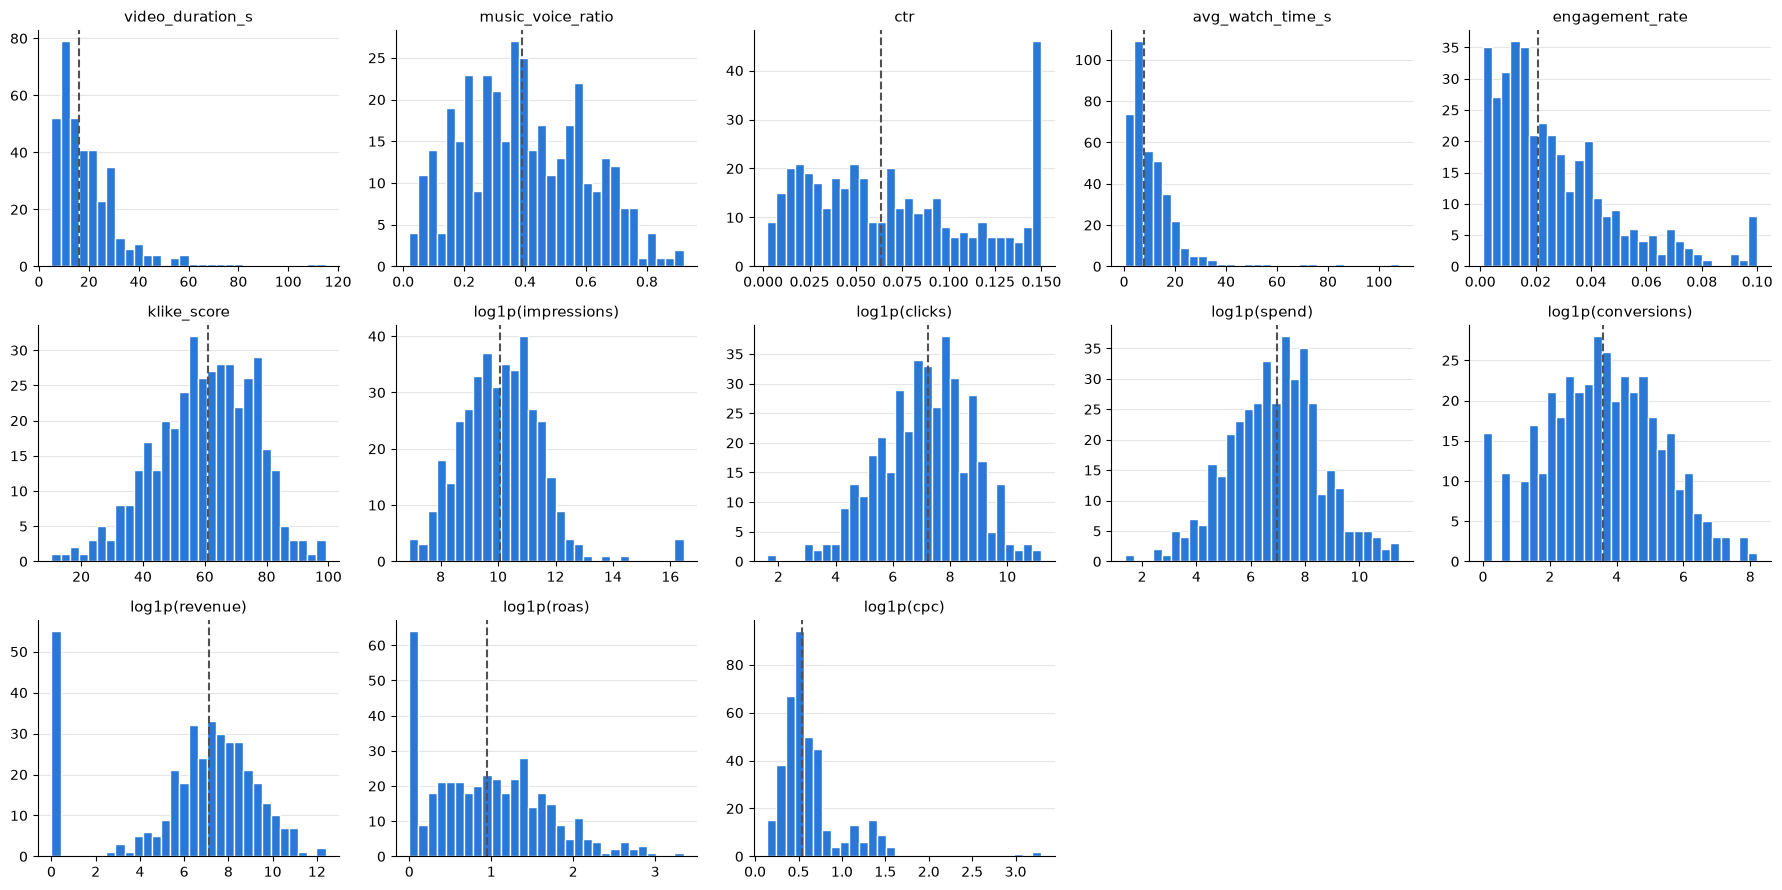

In [8]:
colunas_volume = ["impressions", "clicks", "spend", "conversions", "revenue", "roas", "cpc"]
colunas_normais = ["video_duration_s", "music_voice_ratio", "ctr", "avg_watch_time_s", "engagement_rate", "klike_score"]

fig, eixos = plt.subplots(3, 5, figsize=(18, 9))
for ax, coluna in zip(eixos.flat, colunas_normais + colunas_volume):
    valores = treino[coluna].dropna()
    if coluna in colunas_volume:
        valores = np.log1p(valores)
        ax.set_title(f"log1p({coluna})", fontsize=11)
    else:
        ax.set_title(coluna, fontsize=11)
    ax.hist(valores, bins=30, color=AZUL, edgecolor="white")
    ax.axvline(valores.median(), color=CINZA, linestyle="--")
    estilo_limpo(ax)
for ax in eixos.flat[len(colunas_normais + colunas_volume):]:
    ax.remove()
plt.tight_layout()
plt.show()

In [9]:
# O log resolve a assimetria? (skew perto de 0 = simétrico)
pd.DataFrame({"skew original": treino[colunas_volume].skew(),
              "skew depois do log1p": np.log1p(treino[colunas_volume]).skew()}).round(2)

,skew original,skew depois do log1p
impressions,9.82,0.81
clicks,5.34,-0.23
spend,5.74,-0.02
conversions,6.05,-0.02
revenue,8.95,-1.00
roas,3.10,0.49
cpc,9.36,2.92


**Pelos histogramas e tabelas:**

- **As métricas de volume têm cauda longa:** a média de impressions é 7,7 vezes a mediana (skew 9,8). Poucas campanhas gigantes puxam a média. Por isso **uso a mediana** como número de referência em toda a análise.
- **O log1p resolve quase tudo:** o skew do spend cai de 5,7 para 0,0. No cpc continua alto (2,9): o log ajuda, mas não faz milagre.
- **O `klike_score` é simétrico** (skew −0,33; média 60,1 e mediana 61,2, quase iguais). Para a Parte 2, isso quer dizer que não preciso transformar a nota.
- Dois detalhes estranhos: um **monte de criativos com CTR exatamente 0,15** e com engajamento exatamente 0,10, e alguns impressions isolados muito à direita. Investigo os dois no passo 4.

## Passo 4: as contas entre as métricas batem?

Várias métricas são contas feitas com outras, então dá para conferir cada linha:

| Regra | Por quê |
|---|---|
| `ctr = clicks ÷ impressions` | definição do CTR |
| `cpc = spend ÷ clicks` | definição do CPC |
| `roas = revenue ÷ spend` | definição do ROAS |
| `clicks ≤ impressions`, `conversions ≤ clicks` | não dá para clicar sem ver, nem converter sem clicar |
| `avg_watch_time_s ≤ video_duration_s` | não dá para assistir mais do que o vídeo dura |

Os valores informados vêm arredondados (o CTR tem 4 casas, o CPC tem centavos), então uma conta "não bate" só se o valor informado fugir **mais de 50%** do calculado. Arredondamento muda poucos por cento; erro de digitação muda muito mais.

In [10]:
def conta_nao_bate(calculado, informado):
    """True quando o valor informado foge mais de 50% da conta."""
    return (calculado / informado - 1).abs() > 0.5


conferencia = pd.Series({
    "ctr ≠ clicks ÷ impressions": conta_nao_bate(treino["clicks"] / treino["impressions"], treino["ctr"]).sum(),
    "cpc ≠ spend ÷ clicks": conta_nao_bate(treino["spend"] / treino["clicks"], treino["cpc"]).sum(),
    "roas ≠ revenue ÷ spend": ((treino["roas"] > 0) & conta_nao_bate(treino["revenue"] / treino["spend"], treino["roas"])).sum(),
    "clicks > impressions": (treino["clicks"] > treino["impressions"]).sum(),
    "conversions > clicks": (treino["conversions"] > treino["clicks"]).sum(),
    "watch time > duração": (treino["avg_watch_time_s"] > treino["video_duration_s"]).sum(),
}, name="linhas com problema")
conferencia.to_frame()

,linhas com problema
ctr ≠ clicks ÷ impressions,4
cpc ≠ spend ÷ clicks,6
roas ≠ revenue ÷ spend,2
clicks > impressions,0
conversions > clicks,0
watch time > duração,0


### 4a. Impressions corrompidas

Nestas linhas, `clicks` e `ctr` concordam entre si, e só `impressions` está fora. Num gráfico de cliques × impressões, elas aparecem longe de todas as outras campanhas.

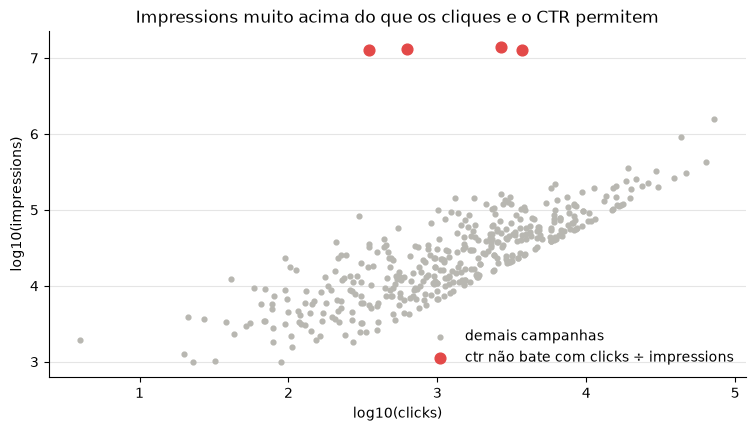

,campaign_id,platform,impressions,clicks,ctr,impressions_pela_conta
231,KLK-0232,TikTok,12594257,345,0.0295,11695.0
257,KLK-0258,TikTok,12873562,3704,0.0426,86948.0
412,KLK-0413,LinkedIn,14052761,2695,0.0374,72059.0
147,KLK-0148,TikTok,13007321,629,0.0148,42500.0


In [11]:
impressions_erradas = conta_nao_bate(treino["clicks"] / treino["impressions"], treino["ctr"])

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.scatter(np.log10(treino["clicks"]), np.log10(treino["impressions"]), s=12, color="#b8b7b1", label="demais campanhas")
ax.scatter(np.log10(treino.loc[impressions_erradas, "clicks"]), np.log10(treino.loc[impressions_erradas, "impressions"]),
           s=60, color="#e34948", label="ctr não bate com clicks ÷ impressions")
ax.set_xlabel("log10(clicks)")
ax.set_ylabel("log10(impressions)")
ax.set_title("Impressions muito acima do que os cliques e o CTR permitem")
ax.legend(frameon=False)
estilo_limpo(ax)
plt.show()

treino.loc[impressions_erradas, ["campaign_id", "platform", "impressions", "clicks", "ctr"]].assign(
    impressions_pela_conta=(treino["clicks"] / treino["ctr"]).round())

**Correção:** `impressions = clicks ÷ ctr`. Corrijo em vez de apagar a linha porque o resto do criativo está certo.

In [12]:
corrigido = treino.copy()
corrigido.loc[impressions_erradas, "impressions"] = (
    corrigido["clicks"] / corrigido["ctr"])[impressions_erradas].round().astype("int64")

### 4b. CPC que não bate: o "voto da maioria"

O spend aparece em duas contas: `cpc = spend ÷ clicks` e `roas = revenue ÷ spend`. Então, quando o cpc não bate, o roas desempata:
- se `revenue ÷ roas` dá o spend informado, o spend está certo, e o errado é o **cpc**;
- se não dá, o errado é o **spend**.

In [13]:
cpc_nao_bate = conta_nao_bate(corrigido["spend"] / corrigido["clicks"], corrigido["cpc"])
votacao = corrigido.loc[cpc_nao_bate, ["campaign_id", "category", "clicks", "cpc", "spend", "revenue", "roas"]].copy()
votacao["spend pela conta do cpc"] = votacao["cpc"] * votacao["clicks"]
votacao["spend pela conta do roas"] = votacao["revenue"] / votacao["roas"]
spend_confirmado = (votacao["roas"] > 0) & ~conta_nao_bate(votacao["spend pela conta do roas"], votacao["spend"])
votacao["veredito"] = np.where(spend_confirmado, "erro no cpc",
                               np.where(votacao["roas"] > 0, "erro no spend", "empate (revenue = 0)"))
votacao.round(2)

,campaign_id,category,clicks,cpc,spend,revenue,roas,spend pela conta do cpc,spend pela conta do roas,veredito
239,KLK-0240,SaaS,2825,24.17,2768.50,11936.58,4.31,68280.25,2769.51,erro no cpc
258,KLK-0259,Lead Gen,20,0.27,95811.69,72.62,13.45,5.40,5.40,erro no spend
99,KLK-0100,E-commerce,951,20.00,370.89,1162.54,3.13,19020.00,371.42,erro no cpc
223,KLK-0224,Branding,17670,1.22,85023.80,0.00,0.00,21557.40,NaN,empate (revenue = 0)
415,KLK-0416,SaaS,1538,26.05,1138.12,2510.55,2.21,40064.90,1136.00,erro no cpc
108,KLK-0109,App Install,205,1.18,50544.77,63.87,0.26,241.90,245.65,erro no spend


**O empate.** Numa campanha de Branding, `revenue = 0`, então o roas não ajuda. Desempato pelo bom senso: comparo o CPM (custo por mil impressões) que cada versão daria com os CPMs das outras campanhas do Meta.

In [14]:
empate = votacao[votacao["veredito"] == "empate (revenue = 0)"]
for _, linha in empate.iterrows():
    original = corrigido.loc[corrigido["campaign_id"] == linha["campaign_id"]].iloc[0]
    outras_meta = corrigido[(corrigido["platform"] == original["platform"]) & ~cpc_nao_bate & ~impressions_erradas]
    cpm_outras = outras_meta["spend"] / outras_meta["impressions"] * 1000
    print(f"{linha['campaign_id']} ({original['platform']}, {original['category']})")
    print(f"  se o spend estiver certo: CPM = {original['spend'] / original['impressions'] * 1000:.0f}")
    print(f"  se o cpc estiver certo:   CPM = {linha['spend pela conta do cpc'] / original['impressions'] * 1000:.0f}")
    print(f"  CPM nas outras campanhas {original['platform']}: mediana {cpm_outras.median():.0f}, máximo {cpm_outras.max():.0f}")

KLK-0224 (Meta, Branding)
  se o spend estiver certo: CPM = 722
  se o cpc estiver certo:   CPM = 183
  CPM nas outras campanhas Meta: mediana 49, máximo 167


**Desempate:** com o spend original, o CPM seria 722, mais de 4 vezes o maior CPM das outras campanhas do Meta (167). Com o cpc certo, o CPM fica em 183, um pouco acima do máximo, mas possível. Então trato como **erro no spend**, igual às outras duas linhas com spend errado. Como é uma campanha de Branding, ela nem entra na análise de ROAS, então o risco dessa escolha é pequeno.

In [15]:
erro_no_cpc = cpc_nao_bate & corrigido["campaign_id"].isin(votacao.loc[votacao["veredito"] == "erro no cpc", "campaign_id"])
erro_no_spend = cpc_nao_bate & ~erro_no_cpc  # inclui o empate, decidido acima

antes = corrigido.copy()
corrigido.loc[erro_no_cpc, "cpc"] = (corrigido["spend"] / corrigido["clicks"])[erro_no_cpc].round(2)
corrigido.loc[erro_no_spend, "spend"] = (corrigido["cpc"] * corrigido["clicks"])[erro_no_spend].round(2)
corrigido.loc[erro_no_spend, "roas"] = (corrigido["revenue"] / corrigido["spend"])[erro_no_spend].round(2)

**Tabela antes/depois** das 10 linhas corrigidas (impressions, cpc e spend):

In [16]:
linhas_corrigidas = impressions_erradas | cpc_nao_bate
antes_depois = pd.concat({"antes": treino.loc[linhas_corrigidas, ["impressions", "cpc", "spend", "roas"]],
                          "depois": corrigido.loc[linhas_corrigidas, ["impressions", "cpc", "spend", "roas"]]}, axis=1)
antes_depois.insert(0, "campaign_id", treino.loc[linhas_corrigidas, "campaign_id"])
antes_depois

campaign_id       antes                              depois                       
                impressions    cpc     spend   roas impressions   cpc     spend   roas
239    KLK-0240      135857  24.17   2768.50   4.31      135857  0.98   2768.50   4.31
258    KLK-0259        1252   0.27  95811.69  13.45        1252  0.27      5.40  13.45
99     KLK-0100       13342  20.00    370.89   3.13       13342  0.39    370.89   3.13
231    KLK-0232    12594257   0.47    162.15   0.48       11695  0.47    162.15   0.48
223    KLK-0224      117801   1.22  85023.80   0.00      117801  1.22  21557.40   0.00
257    KLK-0258    12873562   0.55   2037.20   0.33       86948  0.55   2037.20   0.33
412    KLK-0413    14052761   3.43   9243.85   0.24       72059  3.43   9243.85   0.24
147    KLK-0148    13007321   0.54    339.66   0.00       42500  0.54    339.66   0.00
415    KLK-0416       32532  26.05   1138.12   2.21       32532  0.74   1138.12   2.21
108    KLK-0109        3701   1.18  50544.77   0.26        3701  1.18    241.90   0.26

In [17]:
# Conferência: depois das correções, as três contas batem em todas as linhas
assert not conta_nao_bate(corrigido["clicks"] / corrigido["impressions"], corrigido["ctr"]).any()
assert not conta_nao_bate(corrigido["spend"] / corrigido["clicks"], corrigido["cpc"]).any()
assert not ((corrigido["roas"] > 0) & conta_nao_bate(corrigido["revenue"] / corrigido["spend"], corrigido["roas"])).any()
print("Todas as contas batem depois da correção")

Todas as contas batem depois da correção


### 4c. Valores "cortados" no CTR e no engajamento

Nenhum CTR passa de 0,15 e nenhum engajamento passa de 0,10, e há um monte de criativos **exatamente** nesses valores. Parece que o dado foi cortado num teto: quem tinha mais ficou registrado como 0,15. Não dá para saber o valor verdadeiro, então não corrijo; só aviso nas conclusões.

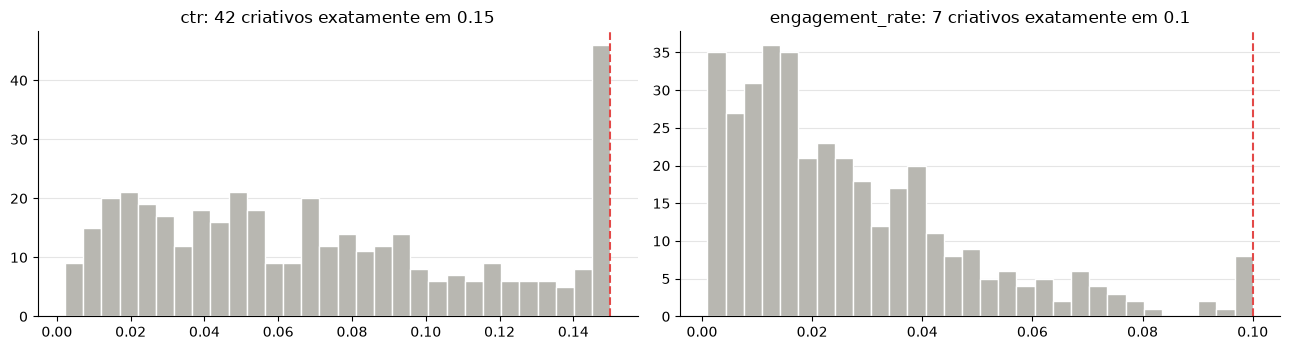

In [18]:
fig, eixos = plt.subplots(1, 2, figsize=(13, 3.6))
for ax, (coluna, teto) in zip(eixos, [("ctr", 0.15), ("engagement_rate", 0.10)]):
    valores = corrigido[coluna].dropna()
    ax.hist(valores, bins=30, color="#b8b7b1", edgecolor="white")
    no_teto = (valores == teto).sum()
    ax.axvline(teto, color="#e34948", linestyle="--")
    ax.set_title(f"{coluna}: {no_teto} criativos exatamente em {teto}")
    estilo_limpo(ax)
plt.tight_layout()
plt.show()

In [19]:
# O corte atinge mais os criativos bons? % de criativos no teto do CTR, com e sem gancho
corrigido.groupby("has_hook").agg(criativos=("ctr", "size"), pct_no_teto=("ctr", lambda s: (s == 0.15).mean() * 100)).round(1)

,criativos,pct_no_teto
has_hook,,
False,194,5.7
True,206,15.0


### 4d. Revenue = 0 no Branding

In [20]:
corrigido.groupby("category").agg(
    criativos=("revenue", "size"),
    revenue_zero=("revenue", lambda s: (s == 0).sum()),
    conversoes_medianas=("conversions", "median"),
    roas_mediano=("roas", "median"),
)

,criativos,revenue_zero,conversoes_medianas,roas_mediano
category,,,,
App Install,68,0,102.5,0.47
Branding,49,47,7.0,0.00
E-commerce,137,1,39.0,2.15
Lead Gen,73,2,29.0,2.31
SaaS,73,5,38.0,3.29


**Resumo do passo 4:**
- **10 linhas com erro, todas corrigidas por conta:** 4 impressions (12 a 14 milhões, quando cliques e CTR davam de 11 mil a 87 mil), 3 cpc e 3 spend (incluindo o empate).
- **CTR e engajamento parecem cortados num teto:** 42 criativos com CTR exatamente 0,15 e 7 com engajamento exatamente 0,10. O corte pega mais os vídeos com gancho (15% deles estão no teto, contra 5,7% dos sem gancho). Consequência: **o efeito do gancho no CTR fica subestimado** (os melhores vídeos "batem no teto" e não mostram o quanto são melhores).
- **ROAS não se aplica a Branding:** 47 das 49 campanhas de Branding têm revenue = 0, mas têm conversões (mediana de 7). Campanha de marca não é feita para vender, então ROAS não mede o que ela quer. **Branding fica fora de toda análise de ROAS e revenue** (filtro `category != "Branding"`). Os poucos zeros nas outras categorias são campanhas que de fato não venderam.

## Passo 5: o que está faltando, e como preencher?

In [21]:
colunas_com_vazio = corrigido.columns[corrigido.isna().any()]
faltantes = pd.DataFrame({"vazios": corrigido[colunas_com_vazio].isna().sum(),
                          "% vazio": (corrigido[colunas_com_vazio].isna().mean() * 100).round(1)})
faltantes.sort_values("vazios", ascending=False)

,vazios,% vazio
has_subtitle,36,9.0
video_duration_s,30,7.5
music_voice_ratio,29,7.2
engagement_rate,27,6.8
revenue,22,5.5
avg_watch_time_s,22,5.5
cpc,20,5.0


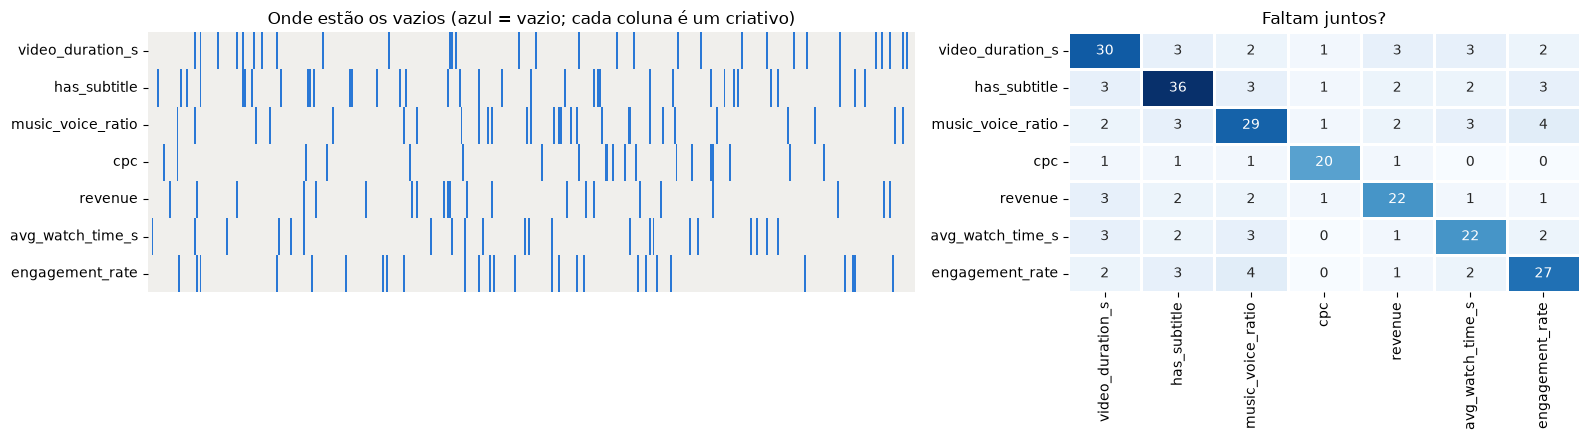

In [22]:
fig, eixos = plt.subplots(1, 2, figsize=(16, 4.5), gridspec_kw={"width_ratios": [3, 2]})
# Esquerda: cada coluna do gráfico é um criativo; azul = valor vazio
sns.heatmap(corrigido[colunas_com_vazio].isna().T, cmap=["#f0efec", AZUL], cbar=False, ax=eixos[0], xticklabels=False)
eixos[0].set_title("Onde estão os vazios (azul = vazio; cada coluna é um criativo)")
# Direita: em quantos criativos duas colunas estão vazias ao mesmo tempo (diagonal = total da coluna)
vazio = corrigido[colunas_com_vazio].isna().astype(int)
sns.heatmap(vazio.T @ vazio, annot=True, fmt="d", cmap="Blues", cbar=False, ax=eixos[1], linewidths=2, linecolor="white")
eixos[1].set_title("Faltam juntos?")
plt.tight_layout()
plt.show()

**Os buracos têm padrão?** Se os vazios caem em qualquer criativo, ao acaso, preencher não distorce a análise. Se caem mais em algum tipo de criativo (por exemplo, só nos de nota baixa), preencher pode esconder um padrão.

Comparo a mediana dos criativos **sem** o valor com a mediana de todos, em três números que nunca estão vazios: a nota, o CTR e o gasto (pela mediana). Mas grupos pequenos (20 a 36 criativos) variam muito por puro acaso. Então preciso de uma **régua do acaso**: sorteio 1.000 grupos aleatórios do mesmo tamanho e vejo quanto a mediana deles muda só por sorte. Se a diferença real fica dentro do que o acaso produz em 95% dos sorteios, não há sinal de padrão.

In [23]:
gerador = np.random.default_rng(42)
linhas = []
for coluna in colunas_com_vazio:
    vazio = corrigido[coluna].isna()
    for metrica in ["klike_score", "ctr", "spend"]:
        mediana_geral = corrigido[metrica].median()
        diferenca_real = (corrigido.loc[vazio, metrica].median() / mediana_geral - 1) * 100  # sem valor × todos
        # Régua do acaso: grupos sorteados com o mesmo número de criativos
        sorteios = [corrigido[metrica].sample(vazio.sum(), random_state=gerador.integers(1_000_000)).median()
                    for _ in range(1000)]
        diferencas_acaso = (np.array(sorteios) / mediana_geral - 1) * 100
        limite = np.percentile(np.abs(diferencas_acaso), 95)
        linhas.append({"coluna com vazio": coluna, "métrica": metrica, "vazios": vazio.sum(),
                       "diferença real (%)": round(diferenca_real), "acaso chega a ±(%)": round(limite),
                       "fora do acaso?": "SIM" if abs(diferenca_real) > limite else "não"})
padrao = pd.DataFrame(linhas)
padrao

,coluna com vazio,métrica,vazios,diferença real (%),acaso chega a ±(%),fora do acaso?
0,video_duration_s,klike_score,30,5,11,não
1,video_duration_s,ctr,30,5,34,não
2,video_duration_s,spend,30,-37,87,não
3,has_subtitle,klike_score,36,1,10,não
4,has_subtitle,ctr,36,-29,33,não
5,has_subtitle,spend,36,-12,66,não
6,music_voice_ratio,klike_score,29,4,11,não
7,music_voice_ratio,ctr,29,12,39,não
8,music_voice_ratio,spend,29,14,89,não
9,cpc,klike_score,20,8,14,não


In [24]:
# % de vazios em cada plataforma
(corrigido[colunas_com_vazio].isna().groupby(corrigido["platform"]).mean().T * 100).round(0)

platform,LinkedIn,Meta,TikTok
video_duration_s,9.0,6.0,9.0
has_subtitle,9.0,8.0,10.0
music_voice_ratio,12.0,6.0,6.0
cpc,3.0,5.0,6.0
revenue,6.0,5.0,6.0
avg_watch_time_s,2.0,5.0,8.0
engagement_rate,8.0,7.0,6.0


**Lendo os vazios:**
- São poucos: de 5% a 9% em 7 colunas, espalhados, e quase nunca faltam juntos.
- **Os buracos não têm padrão:** em 19 das 21 comparações, a diferença fica dentro do que o acaso produz. A exceção é o `cpc`: os 20 criativos sem cpc têm CTR e gasto maiores que a média. Isso não atrapalha, porque o cpc vazio é recalculado pela conta exata (`spend ÷ clicks`), e não por um chute.
- Nenhuma plataforma concentra os vazios (de 2% a 12% em cada coluna).

**Como trato cada coluna:**

| Coluna | Tipo | Tratamento | Por quê |
|---|---|---|---|
| `cpc`, `revenue` | dá para calcular | `cpc = spend ÷ clicks`; `revenue = roas × spend` | é a definição da métrica: é conta, não chute |
| `video_duration_s`, `music_voice_ratio`, `engagement_rate` | número | mediana **da plataforma** | a duração típica muda muito de uma rede para outra (ver abaixo) |
| `avg_watch_time_s` | número com regra | duração × fração mediana assistida na plataforma | garante que o tempo assistido nunca passe da duração |
| `has_subtitle` | sim/não | vira "desconhecido" | "não sei se tem legenda" é diferente de "não tem legenda" |

Antes de preencher, crio um **indicador de faltante** para cada coluna preenchida: uma coluna 0/1 que vale 1 quando o valor original estava vazio. Preencher apaga a informação de quais valores foram inventados; o indicador guarda isso. Ele serve para duas coisas: medir efeitos só com valores reais (perguntas 1.2 e 1.3) e deixar o modelo da Parte 2 usar o fato de o valor faltar, se isso ajudar.

**Mediana geral ou da plataforma? E por que não um método mais esperto?** Comparo quatro jeitos de preencher a duração:
- **mediana geral** de todo o treino;
- **mediana da plataforma** (`groupby` + `transform`);
- **KNNImputer:** procura os 10 criativos mais parecidos (nas outras colunas) e usa a média deles;
- **IterativeImputer:** faz uma regressão que prevê a duração a partir das outras colunas.

Para saber qual acerta mais, faço um teste: escondo 10% das durações que eu **conheço**, preencho com cada método e meço o **MAE** (o erro médio, em segundos) contra o valor verdadeiro. Repito 20 vezes com sorteios diferentes e tiro a média.

Um cuidado: só uso, para ajudar, colunas que existem **antes de postar** (plataforma, categoria, formato, gancho...). O tempo assistido só existe depois que o vídeo roda; usá-lo para adivinhar a duração seria trapaça na Parte 2.

In [25]:
from sklearn.experimental import enable_iterative_imputer  # noqa: F401 (necessário para liberar o IterativeImputer)
from sklearn.impute import IterativeImputer, KNNImputer
from sklearn.preprocessing import StandardScaler

# Colunas de antes de postar, em formato de número (cada categoria vira uma coluna 0/1)
ajudantes = pd.get_dummies(corrigido[["platform", "category", "objective", "target_audience_age", "format", "text_density"]],
                           dtype=float)
ajudantes[["is_retargeting", "has_cta", "has_hook", "has_face"]] = corrigido[["is_retargeting", "has_cta", "has_hook", "has_face"]].astype(float)


def preencher_com_modelo(imputador, tabela, coluna):
    """KNN e Iterative precisam das colunas na mesma escala: padroniza, preenche e volta para segundos."""
    escala = StandardScaler().fit(tabela)
    preenchida = escala.inverse_transform(imputador.fit_transform(escala.transform(tabela)))
    return pd.Series(preenchida[:, tabela.columns.get_loc(coluna)], index=tabela.index)


def testar_metodos(coluna, repeticoes=20):
    conhecidos = corrigido.index[corrigido[coluna].notna()]
    erros = {"mediana geral": [], "mediana da plataforma": [], "KNNImputer": [], "IterativeImputer": []}
    for rodada in range(repeticoes):
        escondidos = np.random.default_rng(42 + rodada).choice(conhecidos, int(0.1 * len(conhecidos)), replace=False)
        valores = corrigido[coluna].copy()
        valores[escondidos] = np.nan
        verdade = corrigido.loc[escondidos, coluna]
        tabela = ajudantes.assign(**{coluna: valores})
        palpites = {
            "mediana geral": valores.fillna(valores.median()),
            "mediana da plataforma": valores.fillna(valores.groupby(corrigido["platform"]).transform("median")),
            "KNNImputer": preencher_com_modelo(KNNImputer(n_neighbors=10), tabela, coluna),
            "IterativeImputer": preencher_com_modelo(IterativeImputer(random_state=42, max_iter=20), tabela, coluna),
        }
        for metodo, palpite in palpites.items():
            erros[metodo].append((palpite[escondidos] - verdade).abs().mean())
    return pd.Series({metodo: np.mean(lista) for metodo, lista in erros.items()})


with warnings.catch_warnings():
    warnings.simplefilter("ignore")  # o IterativeImputer avisa quando não converge; não muda a comparação
    teste_preenchimento = pd.DataFrame({"duração (MAE em segundos)": testar_metodos("video_duration_s"),
                                        "música/voz (MAE, escala 0 a 1)": testar_metodos("music_voice_ratio")})
teste_preenchimento.round(3)

,duração (MAE em segundos),"música/voz (MAE, escala 0 a 1)"
mediana geral,9.930,0.159
mediana da plataforma,9.108,0.160
KNNImputer,10.029,0.162
IterativeImputer,9.660,0.160


In [26]:
# Por que a mediana da plataforma: a duração típica muda muito de uma rede para outra
corrigido.groupby("platform")[["video_duration_s", "music_voice_ratio", "engagement_rate"]].median().round(3)

,video_duration_s,music_voice_ratio,engagement_rate
platform,,,
LinkedIn,23.5,0.37,0.016
Meta,17.0,0.39,0.018
TikTok,12.5,0.40,0.032


**Pelo teste:**
- **Duração:** a mediana da plataforma erra menos (9,1 s) que a mediana geral (9,9 s), o KNNImputer (10,0 s) e o IterativeImputer (9,7 s). Métodos mais complexos não ajudam aqui, porque as colunas de antes de postar quase não dizem nada sobre a duração; a plataforma é o que mais diz (LinkedIn 23,5 s, Meta 17 s, TikTok 12,5 s de mediana).
- **Música/voz:** todos erram igual (cerca de 0,16). Nenhuma coluna ajuda a adivinhar; uso o mais simples, a mediana da plataforma.
- **Engajamento:** o TikTok engaja cerca de duas vezes mais que as outras redes (0,032 contra 0,016 a 0,018), então a mediana geral puxaria o TikTok para baixo e as outras para cima. Também uso a mediana da plataforma.

**Aplicando o tratamento.** As medianas vêm do treino. Na Parte 2, os vazios do teste serão preenchidos com essas mesmas medianas do treino, nunca com medianas calculadas no teste.

In [27]:
# 1) O que dá para calcular
corrigido["cpc"] = corrigido["cpc"].fillna((corrigido["spend"] / corrigido["clicks"]).round(2))
corrigido["revenue"] = corrigido["revenue"].fillna((corrigido["roas"] * corrigido["spend"]).round(2))

# 2) Indicador de faltante: 1 = o valor original estava vazio (criado ANTES de preencher)
colunas_preenchidas = ["video_duration_s", "music_voice_ratio", "avg_watch_time_s", "engagement_rate"]
for coluna in colunas_preenchidas:
    corrigido[f"{coluna}_faltava"] = corrigido[coluna].isna().astype(int)

# 3) Mediana da plataforma
for coluna in ["video_duration_s", "music_voice_ratio", "engagement_rate"]:
    corrigido[coluna] = corrigido[coluna].fillna(corrigido.groupby("platform")[coluna].transform("median"))

# 4) A duração preenchida não pode ficar menor do que o tempo assistido daquele vídeo
menor_que_assistido = corrigido["video_duration_s"] < corrigido["avg_watch_time_s"]
print(f"Durações preenchidas menores que o tempo assistido: {menor_que_assistido.sum()} -> viram o tempo assistido")
corrigido.loc[menor_que_assistido, "video_duration_s"] = corrigido.loc[menor_que_assistido, "avg_watch_time_s"]

Durações preenchidas menores que o tempo assistido: 4 -> viram o tempo assistido


In [28]:
# 5) Tempo assistido = duração × fração mediana assistida na plataforma (só com vídeos que tinham os dois valores)
tinha_os_dois = (corrigido["video_duration_s_faltava"] == 0) & (corrigido["avg_watch_time_s_faltava"] == 0)
fracao_assistida = (corrigido["avg_watch_time_s"] / corrigido["video_duration_s"])[tinha_os_dois]
fracao_mediana = fracao_assistida.groupby(corrigido.loc[tinha_os_dois, "platform"]).median()
print("Fração mediana assistida por plataforma:", fracao_mediana.round(2).to_dict())
estimativa = (corrigido["video_duration_s"] * corrigido["platform"].map(fracao_mediana)).round(1)
corrigido["avg_watch_time_s"] = corrigido["avg_watch_time_s"].fillna(estimativa)

# 6) Legenda: sim / nao / desconhecido
corrigido["has_subtitle"] = corrigido["has_subtitle"].map({True: "sim", False: "nao"}).fillna("desconhecido")

assert corrigido[colunas_preenchidas + ["cpc", "revenue"]].notna().all().all(), "sobrou vazio"
assert (corrigido["avg_watch_time_s"] <= corrigido["video_duration_s"]).all()
print("Sem vazios; tempo assistido nunca passa da duração")
corrigido["has_subtitle"].value_counts()

Fração mediana assistida por plataforma: {'LinkedIn': 0.52, 'Meta': 0.54, 'TikTok': 0.49}
Sem vazios; tempo assistido nunca passa da duração


has_subtitle
sim             207
nao             157
desconhecido     36
Name: count, dtype: int64

## Passo 6: quais valores são extremos? Erro ou verdade?

Duas regras para apontar candidatos a valor extremo:
- **regra do IQR:** o IQR (intervalo interquartil) é a largura dos 50% do meio dos dados. Um valor é extremo se fica mais de 1,5 IQR acima do 3º quartil (ou abaixo do 1º). É a regra dos "pontinhos" do boxplot;
- **z-score:** quantos desvios padrão o valor está longe da média. Acima de 3, é extremo. Problema: um valor gigante puxa a própria média e o desvio padrão, e assim se "esconde".

Uso o treino **antes** das correções do passo 4 (`treino`), para ver se as regras teriam achado os erros sozinhas.

In [29]:
def extremo_pelo_iqr(valores):
    q1, q3 = valores.quantile([0.25, 0.75])
    iqr = q3 - q1
    return (valores < q1 - 1.5 * iqr) | (valores > q3 + 1.5 * iqr)


def extremo_pelo_z(valores):
    z = (valores - valores.mean()) / valores.std()
    return z.abs() > 3


extremos = pd.DataFrame({
    "IQR": {c: extremo_pelo_iqr(treino[c]).sum() for c in colunas_numericas},
    "IQR no log1p": {c: extremo_pelo_iqr(np.log1p(treino[c])).sum() for c in colunas_numericas},
    "z-score > 3": {c: extremo_pelo_z(treino[c]).sum() for c in colunas_numericas},
})
extremos

,IQR,IQR no log1p,z-score > 3
video_duration_s,16,2,7
music_voice_ratio,0,0,0
impressions,34,6,4
clicks,38,1,8
ctr,0,0,0
cpc,54,47,3
spend,49,4,10
conversions,49,0,7
revenue,53,55,4
roas,23,1,11


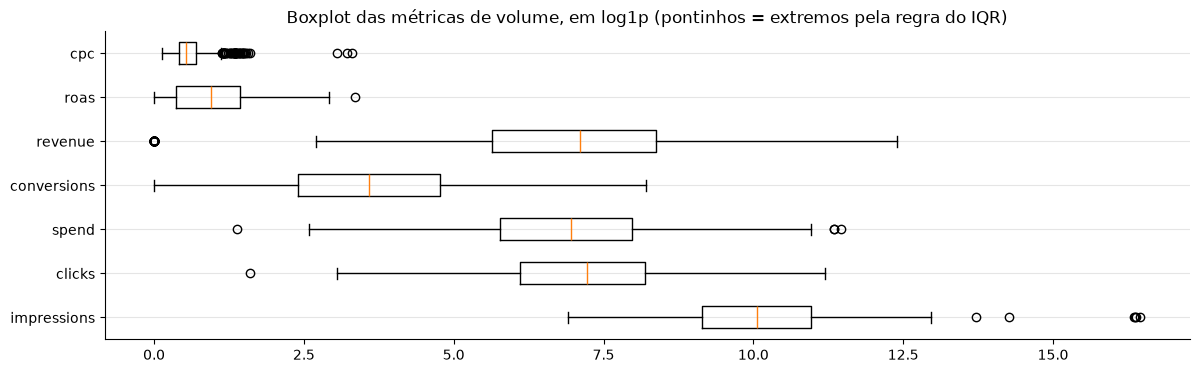

In [30]:
fig, ax = plt.subplots(figsize=(14, 4))
ax.boxplot([np.log1p(treino[c].dropna()) for c in colunas_volume], tick_labels=colunas_volume, orientation="horizontal")
ax.set_title("Boxplot das métricas de volume, em log1p (pontinhos = extremos pela regra do IQR)")
estilo_limpo(ax)
plt.show()

In [31]:
# As regras acham os 10 erros do passo 4? E quantos valores verdadeiros elas marcam junto?
qualquer_z = pd.concat([extremo_pelo_z(treino[c]) for c in colunas_numericas], axis=1).any(axis=1)
print(f"z-score > 3 em alguma coluna: {qualquer_z.sum()} criativos; "
      f"{(qualquer_z & linhas_corrigidas).sum()} dos {linhas_corrigidas.sum()} erros estão entre eles, "
      f"e {(qualquer_z & ~linhas_corrigidas).sum()} são campanhas sem erro")

z-score > 3 em alguma coluna: 50 criativos; 10 dos 10 erros estão entre eles, e 40 são campanhas sem erro


In [32]:
# A correção importa? Média e mediana antes e depois das 10 correções
comparar = ["impressions", "spend", "cpc"]
pd.DataFrame({
    "média antes": treino[comparar].mean(),
    "média depois": corrigido[comparar].mean(),
    "mediana antes": treino[comparar].median(),
    "mediana depois": corrigido[comparar].median(),
}).assign(**{"mudança na média (%)": lambda t: (t["média depois"] / t["média antes"] - 1) * 100,
             "mudança na mediana (%)": lambda t: (t["mediana depois"] / t["mediana antes"] - 1) * 100}).round(1)

,média antes,média depois,mediana antes,mediana depois,mudança na média (%),mudança na mediana (%)
impressions,181050.2,50263.4,23541.0,23486.5,-72.2,-0.2
spend,3924.4,3400.5,1050.7,1028.0,-13.4,-2.2
cpc,1.1,1.0,0.7,0.7,-15.7,0.0


**Erro ou verdade?**
- Em escala normal, a regra do IQR marca dezenas de campanhas de spend (49) e revenue (53). No log, o spend cai para 4: **quase tudo é a cauda longa natural** da mídia paga, não erro. (O revenue continua alto no log por causa dos zeros do Branding, que o log estica.)
- O z-score marca 50 criativos: os 10 erros do passo 4 **e** 40 campanhas sem erro nenhum. As regras genéricas acham candidatos, mas não dizem qual número está errado; quem decide são as contas do passo 4.
- **A correção importa:** consertar só 10 linhas (2,5% do treino) muda a média de impressions em −72% e a mediana em −0,2%. Prova de que os erros existiam e de que a mediana é o número certo para este dado.
- **Decisão:** erros corrigidos (passo 4); valores extremos verdadeiros ficam, e uso a mediana e o log para que eles não dominem a análise.

## Passo 7: colunas novas

Contagens só ficam comparáveis quando divididas por alguma coisa. Aqui:

| Coluna nova | Conta | Para quê |
|---|---|---|
| `retencao` | tempo assistido ÷ duração | a fração do vídeo que a pessoa vê; o tempo assistido sozinho favorece vídeos longos |
| `taxa_conversao` | conversões ÷ cliques | quantos dos cliques viraram conversão |
| `cpm` | spend ÷ impressions × 1000 | custo para aparecer mil vezes; compara o custo entre redes |
| `cpa` | spend ÷ conversões (vazio quando não houve conversão) | custo de cada venda, cadastro ou instalação; a métrica que mais importa para quem compra mídia de conversão |
| `n_boas_praticas` | gancho + CTA + rosto + legenda (0 a 4) | um "checklist" do criativo |
| `faixa_duracao` | `pd.cut` da duração em faixas | ver se existe uma duração ideal sem impor uma reta |
| `mes` | mês da data | ver se a época do ano muda o resultado |

In [33]:
corrigido["retencao"] = corrigido["avg_watch_time_s"] / corrigido["video_duration_s"]
corrigido["taxa_conversao"] = corrigido["conversions"] / corrigido["clicks"]
corrigido["cpm"] = corrigido["spend"] / corrigido["impressions"] * 1000
# Sem conversão, o CPA seria uma divisão por zero (infinito): fica vazio
corrigido["cpa"] = corrigido["spend"] / corrigido["conversions"].where(corrigido["conversions"] > 0)
corrigido["n_boas_praticas"] = (corrigido["has_hook"].astype(int) + corrigido["has_cta"].astype(int)
                                + corrigido["has_face"].astype(int) + (corrigido["has_subtitle"] == "sim").astype(int))
corrigido["faixa_duracao"] = pd.cut(corrigido["video_duration_s"], [0, 10, 15, 20, 30, float("inf")],
                                    labels=["até 10s", "10–15s", "15–20s", "20–30s", "30s ou mais"])
corrigido["mes"] = corrigido["date"].dt.month
print(f"Criativos sem nenhuma conversão (CPA vazio): {corrigido['cpa'].isna().sum()}")
corrigido[["retencao", "taxa_conversao", "cpm", "cpa", "n_boas_praticas"]].describe().round(3)

Criativos sem nenhuma conversão (CPA vazio): 16


,retencao,taxa_conversao,cpm,cpa,n_boas_praticas
count,400.000,400.000,400.000,384.000,400.000
mean,0.542,0.035,66.277,54.026,2.262
std,0.242,0.027,71.986,105.021,0.960
min,0.033,0.000,1.309,2.118,0.000
25%,0.367,0.016,21.227,14.227,2.000
50%,0.507,0.032,45.484,23.883,2.000
75%,0.702,0.047,82.838,51.594,3.000
max,1.000,0.156,496.035,1010.204,4.000


**O que é "boa performance"?** Antes das próximas perguntas, organizo todas as métricas que a base permite medir: em que etapa do funil cada uma fica, se maior ou menor é melhor, e para qual objetivo de campanha ela é a principal.

| Etapa do funil | Métrica | Melhor quando | Principal para o objetivo |
|---|---|---|---|
| Ver | CPM (custo de mil impressões) | menor | awareness (alcance barato) |
| Ver | retenção (fração do vídeo assistida) | maior | awareness |
| Interagir | engajamento | maior | engagement |
| Clicar | CTR | maior | traffic |
| Clicar | CPC | menor | traffic |
| Converter | taxa de conversão (conversões ÷ cliques) | maior | conversions, app_install |
| Converter | CPA (custo por conversão) | menor | conversions, app_install |
| Vender | ROAS | maior | conversions (fora Branding) |
| Tudo | `klike_score` (a nota da Klike) | maior | todos: é o alvo da Parte 2 |

A tabela abaixo mostra a mediana de cada métrica por objetivo: cada objetivo tem um "bom número" diferente.

In [34]:
corrigido.groupby("objective").agg(
    criativos=("ctr", "size"), cpm=("cpm", "median"), retencao=("retencao", "median"),
    engajamento=("engagement_rate", "median"), ctr=("ctr", "median"), cpc=("cpc", "median"),
    taxa_conversao=("taxa_conversao", "median"), cpa=("cpa", "median"), roas=("roas", "median"),
    klike_score=("klike_score", "median")).round(3)

,criativos,cpm,retencao,engajamento,ctr,cpc,taxa_conversao,cpa,roas,klike_score
objective,,,,,,,,,,
app_install,37,36.829,0.473,0.018,0.062,0.60,0.049,10.880,0.660,57.90
awareness,40,37.077,0.570,0.019,0.054,0.70,0.007,66.751,0.000,56.85
conversions,129,45.995,0.504,0.021,0.064,0.71,0.032,22.943,2.420,63.70
engagement,66,42.465,0.537,0.018,0.067,0.68,0.015,47.159,0.840,60.00
traffic,128,52.771,0.518,0.022,0.063,0.75,0.037,20.501,1.625,61.20


**Lendo a tabela por objetivo:**

- **O CTR quase não muda entre objetivos** (5,4% a 6,7%), mas as métricas do fim do funil mudam muito.
- **Awareness quase não converte:** taxa de conversão de 0,7%, CPA mediano de R$67 (o triplo do de conversions, R$23) e ROAS mediano 0. Não faz sentido cobrar venda de uma campanha feita para ser vista; a métrica dela é a **retenção** (57%, a maior entre os objetivos).
- **App install tem o CPA mais baixo** (R$10,9 por instalação) e a maior taxa de conversão (4,9%): instalar um app é mais fácil que comprar.
- **Conversions tem o maior ROAS** (2,4) e a maior nota mediana (63,7).
- **CPA:** mediana de R$23,9, com cauda longa (até R$1.010). 16 criativos não tiveram nenhuma conversão e ficam com o CPA vazio.
- **Decisão:** "boa performance" depende do objetivo. A pergunta 1.2 mede os atributos em todas as métricas e também na métrica principal de cada objetivo.

**A época do ano importa?** Uso o **eta²**: a fração da variação de uma métrica que se explica só por saber o grupo (aqui, o mês). 0 = o mês não diz nada; 1 = o mês diz tudo.

{'ctr': np.float64(0.033), 'klike_score': np.float64(0.026), 'cpm': np.float64(0.016)}


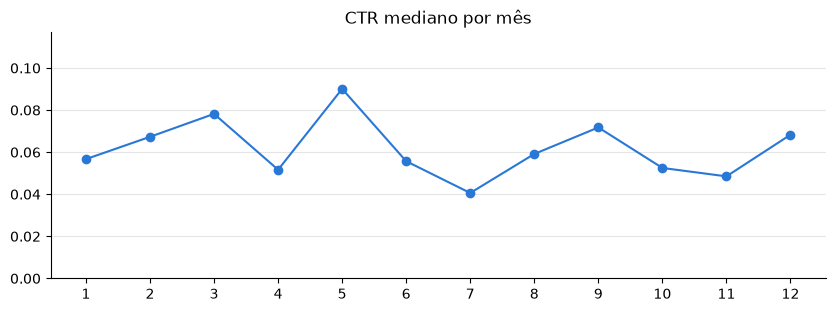

In [35]:
def eta2(valores, grupos):
    """Fração da variação de `valores` explicada só por saber o grupo (0 = nada, 1 = tudo)."""
    media_do_grupo = valores.groupby(grupos).transform("mean")
    return ((media_do_grupo - valores.mean()) ** 2).sum() / ((valores - valores.mean()) ** 2).sum()


print({metrica: round(eta2(corrigido[metrica], corrigido["mes"]), 3) for metrica in ["ctr", "klike_score", "cpm"]})

fig, ax = plt.subplots(figsize=(10, 3.2))
ctr_por_mes = corrigido.groupby("mes")["ctr"].median()
ax.plot(ctr_por_mes.index, ctr_por_mes.values, marker="o", color=AZUL)
ax.set_xticks(range(1, 13))
ax.set_ylim(0, ctr_por_mes.max() * 1.3)
ax.set_title("CTR mediano por mês")
estilo_limpo(ax)
plt.show()

**A época do ano não importa:** o mês explica cerca de 3% da variação do CTR, da nota e do CPM (eta² de 0,03, 0,03 e 0,02). Com 12 meses e 400 criativos, só o acaso já produz um eta² perto de 0,03, então não há sinal de sazonalidade. O mês não entra como coluna na Parte 2.

## Passo 8: a limpeza reaproveitável dá o mesmo resultado?

As Partes 2 e 3 vão precisar da mesma limpeza. Por isso os passos 4, 5 e 7 também estão no arquivo `src/limpeza.py`, uma função curta para cada problema. Aqui confiro que ele dá exatamente o mesmo resultado que o passo a passo acima, e salvo os arquivos limpos. O teste é limpo com as medianas do treino e não é analisado.

In [36]:
from src.limpeza import limpar

treino_limpo = limpar(treino)
pd.testing.assert_frame_equal(treino_limpo, corrigido)  # para com erro se houver qualquer diferença
print("src/limpeza.py dá o mesmo resultado do passo a passo")

teste_limpo = limpar(teste, referencia=treino)
(RAIZ / "data/processed").mkdir(exist_ok=True)
treino_limpo.to_csv(RAIZ / "data/processed/klike_treino_limpo.csv", index=False)
teste_limpo.to_csv(RAIZ / "data/processed/klike_teste_limpo.csv", index=False)
print(f"Salvos: klike_treino_limpo.csv {treino_limpo.shape} e klike_teste_limpo.csv {teste_limpo.shape}")

src/limpeza.py dá o mesmo resultado do passo a passo
Salvos: klike_treino_limpo.csv (400, 37) e klike_teste_limpo.csv (100, 37)


## Resposta à pergunta 1.1

- **O dado:** 400 criativos no treino (100 guardados no teste), de 2024, sem linhas repetidas. Plataformas desbalanceadas (LinkedIn com só 66) e combinações que não existem (TikTok sem vídeo horizontal).
- **Distribuições:** as métricas de volume têm cauda longa, então **uso a mediana** e o log nos gráficos. A nota (`klike_score`) é simétrica.
- **Erros:** **10 linhas com contas que não batiam** (4 impressions, 3 cpc, 3 spend), corrigidas com aritmética e mostradas numa tabela antes/depois.
- **Faltantes:** de 5% a 9% em 7 colunas, sem padrão.
  - O que dá para calcular, calculo (cpc, revenue).
  - Duração, música/voz e engajamento recebem a mediana da plataforma, a escolha que errou menos no teste de preenchimento.
  - O tempo assistido é estimado sem nunca passar da duração.
  - Legenda vazia vira "desconhecido".
  - Um indicador de faltante guarda quais valores eram vazios.
- **Valores extremos:** quase todos são campanhas grandes de verdade e **ficam**; só os erros foram corrigidos.
- **Métricas:** a base mede o funil inteiro (ver, interagir, clicar, converter, vender). Criei retenção, taxa de conversão, CPM e **CPA** (custo por conversão). Cada objetivo de campanha tem a sua métrica principal; a nota `klike_score` resume tudo e é o alvo da Parte 2.
- **Avisos para as próximas perguntas:** o CTR e o engajamento parecem cortados num teto (0,15 e 0,10), e ROAS não se aplica a Branding.